# Solution — Days 2–3 — Forecasting a Lorenz 96 ensemble with a quantum algorithm
### Based on Bravyi et al., arXiv:2507.06198 (2025) and arXiv:2606.08349 (2026)

> **Supervisor version.** Every work cell is filled in and every question has a short answer, in boxes headed *Answers*. Numbers quoted in the answers come from this notebook's own run; SpinPulse results scatter between runs (see Stage 4). Runtime about 7 minutes, mostly Monte Carlo, the 8-qubit circuit and SpinPulse.

## The mission

A weather centre estimates the uncertainty of a forecast by running an **ensemble**: many forecasts from slightly different starts, with random perturbations, averaged at the end. The *Kolmogorian algorithm* of Bravyi and co-authors claims to compute that ensemble average on a quantum computer without running any ensemble members. In two days your team tests the claim on a toy atmosphere, from the equations to a simulated noisy quantum processor.

**The model.** Stochastic Lorenz 96 with $K = 4$ points on a latitude circle, damping $\lambda = 1$, noise strength $q = 2$, no constant forcing ($F = 0$, which the theory requires):

$$dX_k = \big[X_{k-1}(X_{k+1} - X_{k-2}) - \lambda X_k\big]\,dt + \sqrt{q}\,dW_k .$$

**The forecast question.** Start with an anomaly of 1.5 at sites 0 and 2, $x = 1.5\,(e_0 + e_2)$. Predict the ensemble mean at site 1, $\mathbb{E}[X_1(t)]$, for $0 \le t \le 2$. Site 1 is driven only by the product $X_0X_2$, so a linear model predicts nothing here: the answer comes entirely from the nonlinearity.

**The referee.** A 100,000-member Monte Carlo ensemble, computed below. Every number you produce is compared with it.

## Plan for two days

| When | Stage | You have it when |
|---|---|---|
| Day 2 morning | **1. Equations → matrices** | The automatic checks pass for 2 and 4 levels per site |
| Day 2 afternoon | **2. The forecast, computed exactly** | Your forecast agrees with Monte Carlo, and you know how many qubits that takes |
| Day 3 morning | **3. The forecast, computed by a circuit** | A gate circuit reproduces Stage 2, and you can say which error is left |
| Day 3, early afternoon | **4. The circuit on noisy spin qubits** | You can say how good the qubits must be for the circuit to stay useful |
| Day 3, late afternoon | **Report and pitch** | Report table filled, 5-minute pitch |

Checkpoints with a supervisor: end of Stage 1, end of Day 2, end of Stage 3. If a stage runs more than an hour over, ask for help; it is better to finish Stage 4 with help than to stop at Stage 2.

**Working as three.** Every stage has a part that can be done in parallel: someone writes the next function, someone writes its test or plot, someone reads ahead in the primer or the papers. Rotate, so that each of you can explain every stage in the pitch.

**How this notebook works.** Each stage gives the background, the functions to write (name, inputs, outputs), and checks that tell you when they are right. *How* to write them is up to you. Hints are folded under each stage; open them when you are stuck. **Rules:** quote the Monte Carlo standard error next to every comparison, and say which error you are looking at (truncation, Trotter, hardware noise, or sampling).

In [1]:
import numpy as np, math, time, warnings
import scipy.sparse as sp
from scipy.linalg import expm
from scipy.sparse.linalg import expm_multiply, svds
from scipy.special import gammaln
from numpy.polynomial.hermite_e import hermeval
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

from qiskit import QuantumCircuit
from qiskit.circuit.library import StatePreparation, PauliEvolutionGate
from qiskit.quantum_info import SparsePauliOp, Statevector, DensityMatrix

from spin_pulse import HardwareSpecs, Shape, ExperimentalEnvironment, PulseCircuit, DynamicalDecoupling
from spin_pulse.environment.noise import NoiseType

COL = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#6250d6']
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e4e3df', 'lines.linewidth': 2, 'font.size': 10})
print("Imports OK.")

Imports OK.


## Primer: the five ideas you need

Read this together before starting (about 30 minutes). Each idea is used in one stage.

**1. The ensemble mean obeys a linear equation (Stage 1).** For a stochastic equation $dX = f(X)\,dt + \sqrt q\,dW$, the ensemble mean of an observable, $v(t, x) = \mathbb{E}[u_0(X(t)) \mid X(0) = x]$, satisfies the *backward Kolmogorov equation*

$$\partial_t v = f(x)\cdot\nabla v + \tfrac q2\,\Delta v, \qquad v(0, x) = u_0(x).$$

It is a linear PDE, even when $f$ is nonlinear. The price is that $v$ lives on the whole state space. Example: for $f(x) = -\lambda x$ and $u_0 = x$, the solution is $v = x\,e^{-\lambda t}$, and the noise drops out of the mean.

**2. An oscillator basis turns the PDE into a matrix (Stage 1).** Expand $v$ in Hermite functions of each variable. In that basis, multiplying by $x$ and differentiating become combinations of the creation and annihilation operators $a^\dagger$, $a$ of a quantum harmonic oscillator. Basis state $|n\rangle$ means "Hermite function of degree $n$", or "$n$ quanta". The Kolmogorov equation becomes $d\psi/dt = (-\Lambda + C)\,\psi$: $\Lambda$ (damping) counts quanta, $C$ (nonlinearity) moves them between sites. On a computer the basis is cut at $d$ levels, $n = 0, \dots, d-1$.

**3. Several sites means a tensor product (Stage 1).** With $K$ sites, a basis state is a list of occupation numbers $|m_0, m_1, \dots, m_{K-1}\rangle$, so there are $d^K$ states. With $d$ a power of 2, that is $K\log_2 d$ qubits. An operator acting on site $i$ only is $\mathbb 1\otimes\cdots\otimes a\otimes\cdots\otimes\mathbb 1$ (Kronecker product, `np.kron` or `scipy.sparse.kron`).

**4. Unitary parts become circuits (Stage 3).** $C$ is skew-Hermitian ($C^\dagger = -C$), so $e^{Ct}$ is unitary and can be built from gates. Write $iC = \sum_k c_k P_k$ with Pauli strings $P_k$ (such as `XZIY`). Each $e^{-ic_kP_k\delta t}$ is a standard gate sequence. Multiplying them in turn over small steps $\delta t$ approximates $e^{Ct}$: this is a *Trotter* product, with an error that shrinks like $\delta t$. The damping $e^{-\Lambda t}$ is not unitary; here you apply it classically.

**5. Noisy qubits give mixed states (Stage 4).** A noisy processor outputs a density matrix $\rho$ instead of a state vector. Two numbers describe it: **purity** $\mathrm{Tr}\,\rho^2$ (1 for a pure state) and **fidelity** $\langle\psi_{\rm ideal}|\rho|\psi_{\rm ideal}\rangle$ (1 if it is the right state). Spin qubits lose phase coherence on a time scale $T_2^*$; *spin-echo* pulses undo part of that loss.

The demonstration below shows ideas 2 and 3 on a small example. Run it and read the output.

In [2]:
# Idea 2: one oscillator cut at d = 4 levels. a|n> = sqrt(n)|n-1>, so a has sqrt(1), sqrt(2), sqrt(3) above the diagonal.
d = 4
a = np.diag(np.sqrt(np.arange(1, d)), k=1)
print("a =\n", a.round(3))
print("number operator a†a = diag", np.diag(a.T @ a).round(3), " (counts quanta)")
print("[a, a†] = diag", np.diag(a @ a.T - a.T @ a).round(3), " (1 everywhere except the last level: the price of cutting at d)")

# Idea 3: two sites. The annihilation operator of site 1 is identity ⊗ a.
a_site1 = np.kron(np.eye(d), a)
state = np.zeros(d * d); state[np.ravel_multi_index((0, 2), (d, d))] = 1.0     # |m0 = 0, m1 = 2>
out = a_site1 @ state
print("\na_1 |0, 2> =", [f"{v:.3f} |{tuple(int(m) for m in np.unravel_index(i, (d, d)))}>" for i, v in enumerate(out) if abs(v) > 0], " (= sqrt(2) |0, 1>)")

a =
 [[0.    1.    0.    0.   ]
 [0.    0.    1.414 0.   ]
 [0.    0.    0.    1.732]
 [0.    0.    0.    0.   ]]
number operator a†a = diag [0. 1. 2. 3.]  (counts quanta)
[a, a†] = diag [ 1.  1.  1. -3.]  (1 everywhere except the last level: the price of cutting at d)

a_1 |0, 2> = ['1.414 |(0, 1)>']  (= sqrt(2) |0, 1>)


## The referee: Monte Carlo ensemble (provided)

Two ensembles, because there are two versions of the question:

- **fixed start**: every member starts exactly at $x$;
- **noisy start**: members start at $x + z$, $z \sim \mathcal{N}(0, p)$, $p = q/(2\lambda)$ (2025 paper, Eq. 8). This is the case the paper's cost theorem covers.

Runtime: about one minute. Look at the numbers: what do the two curves do, and why do they differ at $t = 0.25$?

In [3]:
K, LAM, Q = 4, 1.0, 2.0
X_ANOM = np.zeros(K); X_ANOM[[0, 2]] = 1.5
OBS = 1
TIMES = np.linspace(0, 2, 9)          # forecast times; the checkers compare at these times

def l96_drift(X):
    # f_k = X_{k-1}(X_{k+1} - X_{k-2}); X has shape (K, members)
    return np.roll(X, 1, 0) * (np.roll(X, -1, 0) - np.roll(X, 2, 0))

def monte_carlo(x0, obs, times, noisy_start, lam=LAM, q=Q, M=100_000, dt=1e-3, seed=0):
    rng = np.random.default_rng(seed)
    X = np.repeat(np.asarray(x0, float)[:, None], M, 1)
    if noisy_start:
        X += rng.normal(0, math.sqrt(q / (2 * lam)), X.shape)
    marks, out = set(np.round(np.asarray(times) / dt).astype(int)), []
    for s in range(int(round(times[-1] / dt)) + 1):
        if s in marks:
            out.append((X[obs].mean(), X[obs].std() / math.sqrt(M)))
        X = X + (l96_drift(X) - lam * X) * dt + math.sqrt(q * dt) * rng.standard_normal(X.shape)
    return np.array(out)

t0 = time.time()
mc_noisy = monte_carlo(X_ANOM, OBS, TIMES, noisy_start=True)
mc_fixed = monte_carlo(X_ANOM, OBS, TIMES, noisy_start=False)
print(f"Monte Carlo done in {time.time() - t0:.0f} s")
print("t            :", TIMES)
print("E[X1], noisy :", mc_noisy[:, 0].round(4), "  max s.e.", mc_noisy[:, 1].max().round(4))
print("E[X1], fixed :", mc_fixed[:, 0].round(4), "  max s.e.", mc_fixed[:, 1].max().round(4))

Monte Carlo done in 52 s
t            : [0.   0.25 0.5  0.75 1.   1.25 1.5  1.75 2.  ]
E[X1], noisy : [0.0012 0.3012 0.3043 0.2404 0.1686 0.1121 0.0683 0.0396 0.0181]   max s.e. 0.0035
E[X1], fixed : [0.     0.3195 0.3534 0.2931 0.2097 0.1424 0.0912 0.0562 0.0298]   max s.e. 0.0032


> **Answers — referee.** Both curves start at 0, rise to a peak near $t \approx 0.4$–$0.5$ and decay. They have the same initial slope: $\mathbb E[f_1] - \lambda\mathbb E[X_1] = \mathbb E[(1.5 + z_0)(1.5 + z_2 - z_3)] = 2.25$ in both cases, because the initial perturbations are independent with zero mean. They separate at second order in $t$, once the random initial values of the other sites feed back through the products: at $t = 0.25$ the fixed start gives 0.320 and the noisy start 0.301, a difference of about 5 standard errors.

## Toolbox (provided)

Run this cell. The tools check your work or handle plumbing (Qiskit and SpinPulse conventions); none of them does a stage for you.

| Tool | Stage | What it does |
|---|---|---|
| `check_tensor(c)` | 1 | Checks your coupling tensor against the Lorenz 96 equations and the paper's conditions |
| `check_generator(Lambda, C, K, d)` | 1 | Checks your damping and nonlinearity matrices, including a fingerprint of $C$ that does not depend on how you order the basis |
| `hermite_function(n, y)` | 2 | $h_n(y) = \mathrm{He}_n(y)/\sqrt{n!}$ |
| `check_forecast(times, values, start)` | 2, 3 | Compares a forecast with the matching Monte Carlo ensemble, in units of its standard error |
| `plot_forecast(curves, start)` | 2, 3 | Plots your curves over the Monte Carlo reference |
| `pauli_decomposition(C)` | 3 | Pauli strings $P_k$ and coefficients $c_k$ with $iC = \sum_k c_kP_k$ |
| `trotter_numpy(op, t, reps, psi)` | 3 | The same product of Pauli rotations as a Qiskit circuit, applied directly to a vector: fast at 8 qubits |
| `spinpulse_channel(circuit, t2s, use_dd)` | 4 | Runs a circuit through SpinPulse's spin-qubit noise model; returns the averaged channel and the compiled circuit |

In [4]:
# Fingerprints of C for K = 4, per-site cutoff d, lam = 1, q = 2: (Frobenius norm, largest singular value).
# Both scale with sqrt(q / (2 lam)) and do not depend on the basis ordering.
_C_REF = {2: (5.6568542495, 2.4494897428), 3: (36.0, 9.2505136235), 4: (117.5755076536, 21.1684691783),
          5: (282.8427124746, 37.93434009), 6: (569.2099788303, 59.05283841)}

def _flag(ok):
    return "PASS " if ok else "CHECK"

def check_tensor(c, K=K):
    """c: dict {(i, j, k): value} or array of shape (K, K, K), meaning f_i(x) = sum_jk c_ijk x_j x_k."""
    if isinstance(c, dict):
        T = np.zeros((K, K, K))
        for (i, j, k), v in c.items():
            T[i, j, k] += v
    else:
        T = np.asarray(c, float)
    x = np.random.default_rng(1).standard_normal(K)
    drift_ok = np.allclose(np.einsum('ijk,j,k->i', T, x, x), l96_drift(x[:, None])[:, 0])
    sym = np.abs(T - T.transpose(0, 2, 1)).max()
    Ts = 0.5 * (T + T.transpose(0, 2, 1))
    diag = max(abs(Ts[i, j, j]) + abs(Ts[j, i, j]) + abs(Ts[j, j, i]) for i in range(K) for j in range(K))
    cyc = np.abs(Ts + Ts.transpose(1, 2, 0) + Ts.transpose(2, 0, 1)).max()
    print(f"{_flag(drift_ok)} reproduces the Lorenz 96 drift at a random state")
    print(f"{_flag(sym < 1e-12)} symmetric in the last two indices (max asymmetry {sym:.1e})")
    print(f"{_flag(diag < 1e-12)} no f_i contains x_i          (max |c_ijj|+|c_jij|+|c_jji| = {diag:.1e})")
    print(f"{_flag(cyc < 1e-12)} c_ijk + c_jki + c_kij = 0     (max {cyc:.1e}; 2025 paper, Eq. 4)")
    print(f"      J = max |c_ijk| = {np.abs(Ts).max():g};  nonzeros per slice c_i.. = {max(int((Ts[i] != 0).sum()) for i in range(K))}")

def check_generator(Lambda, C, K=K, d=None, lam=LAM, q=Q):
    """Lambda, C: dense or sparse matrices on the truncated space. d: levels per site (per-site cutoff)."""
    L, Cs = sp.csr_matrix(Lambda), sp.csr_matrix(C)
    dim = Cs.shape[0]
    skew = abs(Cs + Cs.conj().T).max() if Cs.nnz else 0.0
    print(f"{_flag(skew < 1e-10)} C is skew-Hermitian, so exp(Ct) is unitary  (||C + C†||max = {skew:.1e})")
    offdiag = abs(L - sp.diags(L.diagonal())).max() if L.nnz else 0.0
    print(f"{_flag(offdiag < 1e-12)} Lambda is diagonal")
    if d is not None and dim == d**K:
        n = np.zeros(1)
        for _ in range(K):
            n = np.add.outer(n, np.arange(d)).ravel()
        ok = np.allclose(np.sort(L.diagonal().real), np.sort(lam * n))
        print(f"{_flag(ok)} Lambda = lam x (total number of quanta) on every basis state")
    if dim <= 1024:
        H = (-L + Cs).toarray()
        top = np.linalg.eigvals(H).real.max()
        print(f"{_flag(top < 1e-8)} no growing modes: max Re eig(-Lambda + C) = {top:.1e}")
    if d in _C_REF and dim == d**K:
        scale = math.sqrt(q / (2 * lam))
        fro_ref, sv_ref = (v * scale for v in _C_REF[d])
        fro = sp.linalg.norm(Cs)
        sv = np.linalg.svd(Cs.toarray(), compute_uv=False)[0] if dim <= 1024 else svds(Cs, k=1, return_singular_vectors=False)[0]
        ok = abs(fro - fro_ref) < 1e-6 * fro_ref and abs(sv - sv_ref) < 1e-5 * sv_ref
        print(f"{_flag(ok)} fingerprint of C: ||C||_F = {fro:.4f} (reference {fro_ref:.4f}), "
              f"largest singular value = {sv:.4f} (reference {sv_ref:.4f})")
        if not ok:
            ratio = fro / fro_ref
            print(f"      ratio to reference = {ratio:.4f}. A constant ratio hints at a prefactor; "
                  "otherwise check which operators enter T and how c is symmetrized.")
    else:
        print("      no stored fingerprint for this truncation; structural checks only")

def check_forecast(times, values, start="noisy", label="your forecast"):
    """times: subset of TIMES; values: E[X1] at those times; start: 'noisy' or 'fixed'."""
    mc = mc_noisy if start == "noisy" else mc_fixed
    times, values = np.atleast_1d(times), np.atleast_1d(np.real(values))
    idx = [int(np.argmin(abs(TIMES - t))) for t in times]
    if any(abs(TIMES[i] - t) > 1e-9 for i, t in zip(idx, times)):
        raise ValueError("compare at times contained in TIMES")
    dev = values - mc[idx, 0]
    se = mc[idx, 1].max()
    worst = np.abs(dev).max()
    verdict = "consistent with Monte Carlo" if worst <= 3 * se else "differs from Monte Carlo"
    print(f"{_flag(worst <= 3 * se)} {label} ({start} start): max |forecast - MC| = {worst:.4f} "
          f"= {worst / se:.1f} s.e. (s.e. {se:.4f}) -> {verdict}")
    return worst

def plot_forecast(curves, start="noisy", ax=None, title=None):
    """curves: dict {label: (times, values)}. Draws them over the Monte Carlo mean ± 2 s.e."""
    mc = mc_noisy if start == "noisy" else mc_fixed
    ax = ax or plt.subplots(figsize=(6, 4))[1]
    ax.errorbar(TIMES, mc[:, 0], yerr=2 * mc[:, 1], fmt='o', color='k', ms=4, label="Monte Carlo ±2 s.e.")
    for (lab, (t, v)), col in zip(curves.items(), COL):
        ax.plot(t, np.real(v), '-' if len(t) > 5 else 's', color=col, label=lab)
    ax.set_xlabel("t"); ax.set_ylabel(r"$\mathbb{E}[X_1(t)]$"); ax.legend(frameon=False, fontsize=8)
    ax.set_title(title or f"{start} start", loc='left')
    return ax

def pauli_decomposition(C) -> SparsePauliOp:
    """Pauli strings P_k and real c_k with iC = sum_k c_k P_k (C skew-Hermitian, dimension a power of 2)."""
    dense = C.toarray() if sp.issparse(C) else np.asarray(C)
    p = SparsePauliOp.from_operator(1j * dense)
    return SparsePauliOp(p.paulis, coeffs=p.coeffs.real)

def trotter_numpy(op: SparsePauliOp, t: float, reps: int, psi: np.ndarray) -> np.ndarray:
    """reps repetitions of prod_k exp(-i c_k P_k t/reps), in the order of op: the same product a circuit
    of single-term PauliEvolutionGates applies. Since iC = sum_k c_k P_k, this approximates exp(Ct) psi."""
    mats = [(c.real, SparsePauliOp([P]).to_matrix(sparse=True)) for P, c in zip(op.paulis, op.coeffs)]
    dt, psi = t / reps, np.asarray(psi, complex)
    for _ in range(reps):
        for c_k, P_k in mats:
            psi = math.cos(c_k * dt) * psi - 1j * math.sin(c_k * dt) * (P_k @ psi)
    return psi

def spinpulse_channel(circuit: QuantumCircuit, t2s: float, use_dd: bool = False, noise_type=NoiseType.PINK,
                      num_samples: int = 4, env_duration: int = 2**18):
    """Noise-averaged channel of the WHOLE circuit (including any state preparation inside it) on SpinPulse's
    spin-qubit model. Returns (channel, transpiled circuit). Gate counts: transpiled.count_ops().
    Runtime: tens of seconds per call at 4-6 qubits. Call np.random.seed(...) first for reproducible noise.
    Known bug (spin-pulse 1.1.3): use_dd=True can raise ValueError on some circuits."""
    n = circuit.num_qubits
    hs = HardwareSpecs(n, 0.5, 0.2, 0.01, Shape.GAUSSIAN, ramp_duration=5,
                       dynamical_decoupling=DynamicalDecoupling.SPIN_ECHO if use_dd else None, optim=3)
    isa = hs.gate_transpile(circuit)
    seg = 1 if noise_type == NoiseType.WHITE else env_duration
    env = ExperimentalEnvironment(hardware_specs=hs, noise_type=noise_type, T2S=t2s,
                                  duration=env_duration, segment_duration=seg)
    channel = PulseCircuit.from_circuit(isa, hs, exp_env=env).mean_channel(env, num_samples=num_samples, progress_bar=False)
    return channel, isa

def hermite_function(n: int, y):
    """h_n(y) = He_n(y) / sqrt(n!), with He_n the probabilists' Hermite polynomial (He_0 = 1, He_1 = y, He_2 = y^2 - 1, ...)."""
    coeffs = np.zeros(n + 1); coeffs[n] = 1.0
    return hermeval(y, coeffs) / math.exp(0.5 * gammaln(n + 1))

print("Toolbox loaded.")

Toolbox loaded.


---
## Stage 1 — Equations → matrices (Day 2 morning)

**Background.** The 2025 paper covers equations of the form $dX_i = \big(-\lambda X_i + \sum_{j,k} c_{ijk} X_jX_k\big)dt + \sqrt q\,dW_i$. In the oscillator basis (primer, ideas 2–3) their Kolmogorov equation becomes $d\psi/dt = (-\Lambda + C)\,\psi$ with

$$\Lambda = \lambda\sum_i a_i^\dagger a_i, \qquad C = T - T^{\top}, \qquad T = \sqrt{q/2}\;\lambda^{-1/2}\sum_{ijk} c_{ijk}\,a_j^\dagger a_k^\dagger a_i \quad (\text{2026 paper, Eq. 30}).$$

Reading $T$: it removes one quantum from site $i$ and adds one at site $j$ and one at site $k$, with weight $c_{ijk}$.

**Functions to write**

| Function | Returns |
|---|---|
| `l96_tensor(K)` | dict `{(i, j, k): c_ijk}` with $\sum_{jk} c_{ijk}x_jx_k = x_{i+1}x_{i-1} - x_{i-2}x_{i-1}$ (indices mod $K$), symmetric in $j, k$ |
| `annihilation(d)` | the $d\times d$ matrix $a$ |
| `site_operator(op, i, K, d)` | sparse matrix of `op` acting on site $i$ of $K$ |
| `build_generator(K, d, lam, q)` | `(Lambda, C)` as sparse matrices of size $d^K$ |

**You have it when** `check_tensor` passes, and `check_generator` passes for $d = 2$ and $d = 4$.

**Questions** (keep short answers for the pitch).
1. How many states and qubits does $K = 4$ need at $d = 2$, 4 and 8? How many Pauli strings are in $C$ at $d = 2$ and $d = 4$? (`len(pauli_decomposition(C))`)
2. `check_tensor` tests two conditions of the paper. Show on paper that they mean (i) no $f_i$ contains $x_i$ and (ii) $\sum_i x_if_i = 0$. Which physical property is (ii)? Why would a constant forcing $F$ break it?
3. In $C$, the factor $\sqrt q$ multiplies the physical nonlinearity. Why does more noise make the nonlinearity look *stronger* in oscillator units? (Hint: what is the oscillator's natural length scale?)

<details><summary>Hint: the tensor</summary>

A product $x_ax_b$ can be split as $\tfrac12$ into `c[(i, a, b)]` and $\tfrac12$ into `c[(i, b, a)]`. Remember Python's `%` for periodic indices: `(i - 2) % K`.
</details>

<details><summary>Hint: site operators</summary>

Start from `sp.identity(1)` and loop over the $K$ sites, Kronecker-multiplying by `op` at site $i$ and by `sp.identity(d)` elsewhere. Check on $d = 3$, $K = 2$ against the primer's `np.kron`.
</details>

<details><summary>Hint: building C</summary>

With `a = [site_operator(annihilation(d), i, K, d) for i in range(K)]` and `ad = [x.T for x in a]`, each term of $T$ is `v * ad[j] @ ad[k] @ a[i]`. Writing $C = T - T^\top$ makes $C$ exactly skew-symmetric, even after the cut at $d$ levels.
</details>

In [5]:
def l96_tensor(K):
    # f_i = x_{i+1} x_{i-1} - x_{i-2} x_{i-1}; each product x_a x_b is split evenly between c[i,a,b] and c[i,b,a]
    c = {}
    def add(i, a, b, v):
        for j, k in ((a, b), (b, a)):
            c[(i, j, k)] = c.get((i, j, k), 0.0) + v / 2
    for i in range(K):
        add(i, (i + 1) % K, (i - 1) % K, +1.0)
        add(i, (i - 2) % K, (i - 1) % K, -1.0)
    return {key: v for key, v in c.items() if abs(v) > 1e-15}

def annihilation(d):
    return np.diag(np.sqrt(np.arange(1, d)), k=1)

def site_operator(op, i, K, d):
    out = sp.identity(1, format='csr')
    for k in range(K):
        out = sp.kron(out, sp.csr_matrix(op) if k == i else sp.identity(d, format='csr'), format='csr')
    return out

def build_generator(K, d, lam, q):
    a = [site_operator(annihilation(d), i, K, d) for i in range(K)]
    ad = [x.T.tocsr() for x in a]
    Lambda = sum(lam * ad[i] @ a[i] for i in range(K)).tocsr()
    pref = math.sqrt(q / 2) / math.sqrt(lam)
    T = sp.csr_matrix(Lambda.shape)
    for (i, j, k), v in l96_tensor(K).items():
        T = T + pref * v * (ad[j] @ ad[k] @ a[i])
    return Lambda, (T - T.T).tocsr()

In [6]:
check_tensor(l96_tensor(4))
for d in (2, 4):
    print(f"\n--- d = {d}: {d**4} states on {4 * int(np.log2(d))} qubits")
    Lambda, Cmat = build_generator(4, d, LAM, Q)
    check_generator(Lambda, Cmat, K=4, d=d)
    print(f"      Pauli strings in C: {len(pauli_decomposition(Cmat))}")
print(f"\n--- d = 8: {8**4} states on 12 qubits")

PASS  reproduces the Lorenz 96 drift at a random state
PASS  symmetric in the last two indices (max asymmetry 0.0e+00)
PASS  no f_i contains x_i          (max |c_ijj|+|c_jij|+|c_jji| = 0.0e+00)
PASS  c_ijk + c_jki + c_kij = 0     (max 0.0e+00; 2025 paper, Eq. 4)
      J = max |c_ijk| = 0.5;  nonzeros per slice c_i.. = 4

--- d = 2: 16 states on 4 qubits
PASS  C is skew-Hermitian, so exp(Ct) is unitary  (||C + C†||max = 0.0e+00)
PASS  Lambda is diagonal
PASS  Lambda = lam x (total number of quanta) on every basis state
PASS  no growing modes: max Re eig(-Lambda + C) = 0.0e+00
PASS  fingerprint of C: ||C||_F = 5.6569 (reference 5.6569), largest singular value = 2.4495 (reference 2.4495)
      Pauli strings in C: 8

--- d = 4: 256 states on 8 qubits
PASS  C is skew-Hermitian, so exp(Ct) is unitary  (||C + C†||max = 0.0e+00)
PASS  Lambda is diagonal
PASS  Lambda = lam x (total number of quanta) on every basis state
PASS  no growing modes: max Re eig(-Lambda + C) = 0.0e+00
PASS  fingerprint

> **Answers — Stage 1**
>
> 1. **Sizes.** $d = 2$: 16 states on 4 qubits; $d = 4$: 256 states on 8 qubits; $d = 8$: 4,096 states on 12 qubits. $C$ has 8 Pauli strings at $d = 2$ and 512 at $d = 4$.
> 2. **Conditions.** (i) $c_{ijj} = c_{jij} = c_{jji} = 0$ says that no $f_i$ contains $x_i$, so $\partial f_i/\partial x_i = 0$: the nonlinearity conserves phase-space volume. (ii) $\sum_i x_if_i = \sum_{ijk} c_{ijk}x_ix_jx_k$ vanishes for every $x$ exactly when the fully symmetrized tensor vanishes. With $c$ symmetric in $j, k$, the six permutations sum to $2(c_{ijk} + c_{jki} + c_{kij})$, so the condition is $c_{ijk} + c_{jki} + c_{kij} = 0$. Physically, advection conserves the energy $E = \tfrac12\sum_i x_i^2$. A constant forcing adds $F\sum_i x_i$ to $dE/dt$, an energy input that is not zero, and it is a constant term the paper's class of equations does not contain.
> 3. **Why $\sqrt q$.** The oscillator's natural length scale is the climatological standard deviation $\sqrt p = \sqrt{q/(2\lambda)}$, with $x = \sqrt p\,y$. In $y$ units the drift becomes $\sqrt p\,\sum_{jk} c_{ijk}y_jy_k$. More noise means typical states are larger, and at larger amplitude the quadratic term matters more relative to the linear damping.

---
## Stage 2 — The forecast, computed exactly (Day 2 afternoon)

**Background.** In oscillator units each variable is $y_k = x_k\sqrt{2\lambda/q}$, and basis state $|\mathbf m\rangle = |m_0,\dots,m_{K-1}\rangle$ stands for the function $\prod_k h_{m_k}(y_k)$, $h_n = \mathrm{He}_n/\sqrt{n!}$. Three ingredients turn the matrices of Stage 1 into a forecast:

- **The initial state $\psi(0)$** encodes the observable, $u_0(x) = x_1$. Since $\mathrm{He}_1(y) = y$, we have $x_1 = \sqrt p\,h_1(y_1)$ with $p = q/(2\lambda)$: the state is $\sqrt p$ times "one quantum on site 1".
- **Evolution:** $\psi(t) = e^{t(-\Lambda + C)}\,\psi(0)$, computed exactly with SciPy here (Stage 3 replaces it by a circuit).
- **Readout.** For a **fixed start** $x$, the forecast is $v(t, x) = \sum_{\mathbf m}\psi_{\mathbf m}(t)\prod_k h_{m_k}(y_k)$: the overlap of $\psi(t)$ with a readout vector. For a **noisy start** $x + z$, $z \sim \mathcal N(0, p)$ (the case the paper's theorems cover, 2025, Eqs. 8 and 72–74), average over $z$. In $y$ units the noise $Z$ is standard Gaussian, and $\mathbb E_Z[\mathrm{He}_n(y + Z)] = y^n$. For example, $\mathbb E[(y+Z)^2 - 1] = y^2 + 1 - 1 = y^2$. So the noisy-start readout vector has entries $\prod_k y_k^{m_k}/\sqrt{m_k!}$, and nothing else changes.

**Functions to write**

| Function | Returns |
|---|---|
| `initial_state(K, d, site, lam, q)` | vector of length $d^K$ |
| `readout_fixed(K, d, x0, lam, q)`, `readout_noisy(K, d, x0, lam, q)` | vectors of length $d^K$ |
| `forecast_exact(K, d, x0, site, times, readout, lam, q, nonlinear=True)` | $v(t)$ at each time in `times` |

**You have it when**

1. **Sanity check.** With `nonlinear=False` (i.e. $C = 0$), the forecast at site 0 equals $1.5\,e^{-t}$ to about $10^{-12}$, for both readouts. That is the linear example of primer idea 1.
2. `check_forecast` passes for both starts at some $d$; plot $d = 2, 4, 6$ against Monte Carlo with `plot_forecast`.

**Questions.**
1. What is the smallest $d$ that agrees with Monte Carlo, and how many qubits is that?
2. The fixed and noisy starts give different curves. Which question does a weather centre actually ask?
3. Why does the forecast at site 1 rise and then decay? Answer with the model equation, not the code.

<details><summary>Hint: the position of a basis state</summary>

In a Kronecker-ordered vector, the state $|m_0, \dots, m_{K-1}\rangle$ sits at `np.ravel_multi_index((m_0, ..., m_{K-1}), (d,) * K)`. That matches the ordering of `site_operator` if site 0 is the leftmost factor.
</details>

<details><summary>Hint: readout vectors</summary>

Both are Kronecker products over sites of a length-$d$ vector: $[h_0(y_k), \dots, h_{d-1}(y_k)]$ for the fixed start, $[y_k^n/\sqrt{n!}]_{n<d}$ for the noisy start. Build them with a loop of `np.kron`, like the operators.
</details>

<details><summary>Hint: exact evolution at many times</summary>

`expm_multiply(G, psi0, start=times[0], stop=times[-1], num=len(times), endpoint=True)` returns the state at every time in one call; `G` must be sparse (`.tocsc()`). The forecast is then `states @ readout_vector`.
</details>

In [7]:
def initial_state(K, d, site, lam, q):
    psi = np.zeros(d**K)
    m = np.zeros(K, dtype=int); m[site] = 1
    psi[np.ravel_multi_index(m, (d,) * K)] = math.sqrt(q / (2 * lam))
    return psi

def _kron_over_sites(vectors):
    out = np.array([1.0])
    for v in vectors:
        out = np.kron(out, v)
    return out

def readout_fixed(K, d, x0, lam, q):
    y = np.asarray(x0, float) * math.sqrt(2 * lam / q)
    return _kron_over_sites([[hermite_function(n, yk) for n in range(d)] for yk in y])

def readout_noisy(K, d, x0, lam, q):
    y = np.asarray(x0, float) * math.sqrt(2 * lam / q)
    return _kron_over_sites([[yk**n / math.sqrt(math.factorial(n)) for n in range(d)] for yk in y])

def forecast_exact(K, d, x0, site, times, readout, lam=LAM, q=Q, nonlinear=True):
    Lambda, Cmat = build_generator(K, d, lam, q)
    G = (-Lambda + (Cmat if nonlinear else 0 * Cmat)).tocsc()
    states = expm_multiply(G, initial_state(K, d, site, lam, q), start=times[0], stop=times[-1],
                           num=len(times), endpoint=True)
    return states @ readout(K, d, x0, lam, q)

sanity check, fixed readout, C off: max |v - 1.5 e^(-t)| = 3.3e-16
sanity check, noisy readout, C off: max |v - 1.5 e^(-t)| = 3.3e-16

CHECK exact, d = 2 (noisy start): max |forecast - MC| = 0.1430 = 40.6 s.e. (s.e. 0.0035) -> differs from Monte Carlo
CHECK exact, d = 2 (fixed start): max |forecast - MC| = 0.0938 = 29.8 s.e. (s.e. 0.0032) -> differs from Monte Carlo
PASS  exact, d = 4 (noisy start): max |forecast - MC| = 0.0076 = 2.2 s.e. (s.e. 0.0035) -> consistent with Monte Carlo
PASS  exact, d = 4 (fixed start): max |forecast - MC| = 0.0082 = 2.6 s.e. (s.e. 0.0032) -> consistent with Monte Carlo


PASS  exact, d = 6 (noisy start): max |forecast - MC| = 0.0051 = 1.4 s.e. (s.e. 0.0035) -> consistent with Monte Carlo
PASS  exact, d = 6 (fixed start): max |forecast - MC| = 0.0061 = 1.9 s.e. (s.e. 0.0032) -> consistent with Monte Carlo


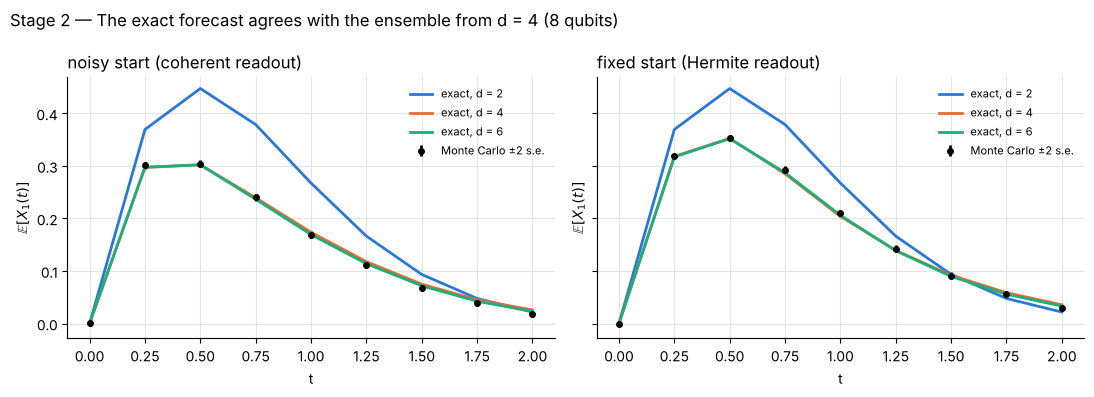

In [8]:
for name, ro in (("fixed", readout_fixed), ("noisy", readout_noisy)):
    v = forecast_exact(4, 3, X_ANOM, 0, TIMES, ro, nonlinear=False)
    print(f"sanity check, {name} readout, C off: max |v - 1.5 e^(-t)| = {np.abs(v - 1.5 * np.exp(-LAM * TIMES)).max():.1e}")
print()
exact = {}
for d in (2, 4, 6):
    for start, ro in (("noisy", readout_noisy), ("fixed", readout_fixed)):
        exact[(start, d)] = forecast_exact(4, d, X_ANOM, OBS, TIMES, ro)
        check_forecast(TIMES, exact[(start, d)], start=start, label=f"exact, d = {d}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, start in zip(axes, ("noisy", "fixed")):
    plot_forecast({f"exact, d = {d}": (TIMES, exact[(start, d)]) for d in (2, 4, 6)}, start=start, ax=ax,
                  title=f"{start} start ({'coherent' if start == 'noisy' else 'Hermite'} readout)")
fig.suptitle("Stage 2 — The exact forecast agrees with the ensemble from d = 4 (8 qubits)", x=0.01, ha='left')
plt.tight_layout(); plt.show()

> **Answers — Stage 2**
>
> 1. **Smallest $d$.** $d = 4$, i.e. 8 qubits (2 per site). At $d = 2$ the forecast misses Monte Carlo by 0.14 (noisy start) and 0.09 (fixed start), about 40 and 30 standard errors. At $d = 4$ it is within 0.008, about 2–3 standard errors; $d = 6$ improves this only slightly, so the remaining gap is mostly Monte Carlo sampling and time-step error.
> 2. **Which question.** A weather centre never knows the initial state exactly: the analysis has an error, and ensemble members start from perturbed states. That is the noisy start, which is also the case covered by the paper's cost theorem. Here the initial spread equals the climatological variance, much larger than a real analysis error.
> 3. **Rise and decay.** $f_1 = X_0(X_2 - X_3)$. At $t = 0$, $X_0 = X_2 = 1.5$ and $X_3 = 0$, so $X_1$ is pushed up at rate 2.25. The anomalies at sites 0 and 2 decay like $e^{-\lambda t}$, so the push on site 1 fades like $e^{-2\lambda t}$, while $X_1$ itself is damped at rate $\lambda$. The forecast peaks when the push and the damping balance, near $t \approx 0.4$–$0.5$, and then decays.

---
## Stage 3 — The forecast, computed by a circuit (Day 3 morning)

**Background.** Replace the exact $e^{C\,\delta t}$ by a gate circuit (primer, idea 4), and apply the damping classically around it. One time step $\delta t$ is

$$e^{-\Lambda\delta t/2}\;\; e^{C\delta t}\;\; e^{-\Lambda\delta t/2}.$$

Because $\Lambda$ is diagonal, $e^{-\Lambda\delta t/2}$ just multiplies each amplitude by $e^{-\lambda|\mathbf m|\delta t/2}$, where $|\mathbf m|$ is its number of quanta. In Qiskit, `PauliEvolutionGate(SparsePauliOp([P], [c]), time=dt)` applies $e^{-icP\,dt}$; since $iC = \sum_k c_kP_k$, a product of these over all terms approximates $e^{C\,dt}$.

**Functions to write**

| Function | Returns |
|---|---|
| `trotter_circuit(op, t, reps)` | Qiskit circuit: `reps` repetitions of one `PauliEvolutionGate` per Pauli term, each for time `t/reps` |
| `forecast_circuit(K, d, x0, site, times, steps_per_unit, readout)` | the forecast with damping + circuit steps |

**You have it when**

1. **Convergence plot** at $d = 2$ (4 qubits): $\|\psi_{\rm circuit} - e^{Ct}\psi\|$ against `reps` = 1, 2, 4, …, 64 on log–log axes. Which slope do you expect?
2. **Forecast plot:** circuit forecast at $d = 2$ and $d = 4$ (32 steps per time unit), together with your Stage 2 curves and Monte Carlo.
3. **Error split at $t = 1$:** truncation error (Stage 2 vs Monte Carlo) and Trotter error (circuit vs Stage 2), for $d = 2$ and $d = 4$. Which one dominates in each case?

**Speed warning.** At $d = 4$ (8 qubits) $C$ has 512 Pauli strings, and Qiskit simulating them gate by gate takes minutes per step. Use the Qiskit circuit at $d = 2$. At $d = 4$, use `trotter_numpy(op, dt, 1, psi)`, which applies exactly the same rotations to a vector; check that it agrees with your circuit at $d = 2$ first.

<details><summary>Hint: comparing states</summary>

A global phase does not change a forecast, but it does change $\|\psi_{\rm circuit} - \psi_{\rm exact}\|$. Multiply the circuit state by `np.exp(-1j * np.angle(np.vdot(exact, circuit_state)))` before comparing. For the initial state, `qc.initialize(psi0 / norm, range(n))` prepares a normalized vector.
</details>

<details><summary>Hint: one damped step with a circuit</summary>

Qiskit's `Statevector` needs a normalized vector, but the damping shrinks the norm. Store the norm, normalize, evolve with `Statevector(psi / nrm).evolve(step_circuit).data`, then multiply by `nrm`.
</details>

<details><summary>Hint: why one gate per term</summary>

A single `PauliEvolutionGate` for the whole sum may be compiled exactly, which hides the Trotter error you are asked to measure.
</details>

In [9]:
def trotter_circuit(op, t, reps):
    n, dt = op.num_qubits, t / reps
    qc = QuantumCircuit(n)
    for _ in range(reps):
        for P, c in zip(op.paulis, op.coeffs):
            qc.append(PauliEvolutionGate(SparsePauliOp([P], [c.real]), time=dt), range(n))
    return qc

def damped_step(psi, half_damp, step):
    # half damping, one step of exp(C dt) (a QuantumCircuit or a function), half damping
    psi = half_damp * psi
    if isinstance(step, QuantumCircuit):
        nrm = np.linalg.norm(psi)
        psi = Statevector(psi / nrm).evolve(step).data * nrm
    else:
        psi = step(psi)
    return half_damp * psi

def forecast_circuit(K, d, x0, site, times, steps_per_unit, readout, lam=LAM, q=Q):
    Lambda, Cmat = build_generator(K, d, lam, q)
    op = pauli_decomposition(Cmat)
    dt = 1.0 / steps_per_unit
    half_damp = np.exp(-Lambda.diagonal() * dt / 2)
    step = trotter_circuit(op, dt, 1) if d == 2 else (lambda psi: trotter_numpy(op, dt, 1, psi))
    psi = initial_state(K, d, site, lam, q).astype(complex)
    ro, out, t_now = readout(K, d, x0, lam, q), [], 0.0
    for t_target in times:
        while t_now < t_target - 1e-9:
            psi = damped_step(psi, half_damp, step); t_now += dt
        out.append(float(np.real(ro @ psi)))
    return np.array(out)

d = 2: 8 Pauli strings; state error at t = 0.5: {1: 0.2315, 2: 0.1156, 4: 0.0577, 8: 0.0288, 16: 0.0144, 32: 0.0072, 64: 0.0036}
Qiskit circuit vs trotter_numpy at d = 2: max difference 1.4e-17



CHECK damping + circuit, d = 2 (2 s) (noisy start): max |forecast - MC| = 0.1507 = 42.8 s.e. (s.e. 0.0035) -> differs from Monte Carlo


CHECK damping + circuit, d = 4 (5 s) (noisy start): max |forecast - MC| = 0.0210 = 6.0 s.e. (s.e. 0.0035) -> differs from Monte Carlo

At t = 1: Monte Carlo 0.1686 ± 0.0033
  d = 2: exact 0.2673, circuit 0.2747 | truncation error +0.0986, Trotter + splitting error +0.0074
  d = 4: exact 0.1737, circuit 0.1896 | truncation error +0.0050, Trotter + splitting error +0.0159


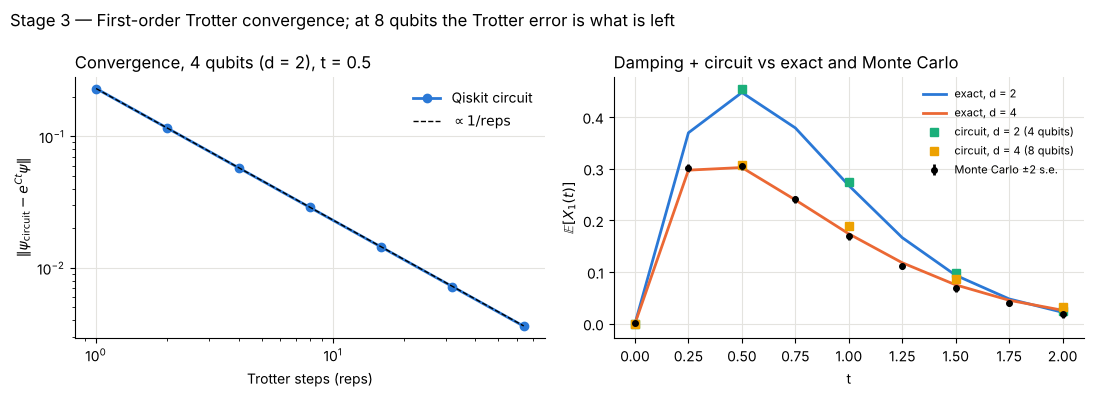

In [10]:
# (1) Convergence of the circuit to exp(Ct) at d = 2 (4 qubits)
_, C2 = build_generator(4, 2, LAM, Q); op2 = pauli_decomposition(C2)
psi0 = initial_state(4, 2, OBS, LAM, Q); psi0 = psi0 / np.linalg.norm(psi0)
T_CONV, REPS = 0.5, [1, 2, 4, 8, 16, 32, 64]
exact_state = expm(C2.toarray() * T_CONV) @ psi0
errs = []
for reps in REPS:
    qc = QuantumCircuit(4); qc.initialize(psi0, range(4))
    sv = Statevector(qc.compose(trotter_circuit(op2, T_CONV, reps))).data
    sv = sv * np.exp(-1j * np.angle(np.vdot(exact_state, sv)))
    errs.append(np.linalg.norm(sv - exact_state))
print(f"d = 2: {len(op2)} Pauli strings; state error at t = {T_CONV}:", {r: round(float(e), 4) for r, e in zip(REPS, errs)})
qc = QuantumCircuit(4); qc.initialize(psi0, range(4))
gap = np.abs(Statevector(qc.compose(trotter_circuit(op2, T_CONV, 4))).data - trotter_numpy(op2, T_CONV, 4, psi0)).max()
print(f"Qiskit circuit vs trotter_numpy at d = 2: max difference {gap:.1e}\n")

# (2) Full algorithm, 32 steps per time unit
T_SUB = TIMES[::2]
circ, runtime = {}, {}
for d in (2, 4):
    t0 = time.time()
    circ[d] = forecast_circuit(4, d, X_ANOM, OBS, T_SUB, 32, readout_noisy)
    runtime[d] = time.time() - t0
    check_forecast(T_SUB, circ[d], start="noisy", label=f"damping + circuit, d = {d} ({runtime[d]:.0f} s)")

# (3) Error split at t = 1 (noisy start)
i_full, i_sub = int(np.argmin(abs(TIMES - 1))), int(np.argmin(abs(T_SUB - 1)))
print(f"\nAt t = 1: Monte Carlo {mc_noisy[i_full, 0]:.4f} ± {mc_noisy[i_full, 1]:.4f}")
for d in (2, 4):
    e, c = exact[("noisy", d)][i_full], circ[d][i_sub]
    print(f"  d = {d}: exact {e:.4f}, circuit {c:.4f} | truncation error {e - mc_noisy[i_full, 0]:+.4f}, "
          f"Trotter + splitting error {c - e:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].loglog(REPS, errs, 'o-', color=COL[0], label="Qiskit circuit")
axes[0].loglog(REPS, errs[0] / np.array(REPS, float), 'k--', lw=1, label=r"$\propto 1/\mathrm{reps}$")
axes[0].set_xlabel("Trotter steps (reps)"); axes[0].set_ylabel(r"$\|\psi_{\rm circuit} - e^{Ct}\psi\|$")
axes[0].set_title("Convergence, 4 qubits (d = 2), t = 0.5", loc='left'); axes[0].legend(frameon=False)
plot_forecast({"exact, d = 2": (TIMES, exact[("noisy", 2)]), "exact, d = 4": (TIMES, exact[("noisy", 4)]),
               "circuit, d = 2 (4 qubits)": (T_SUB, circ[2]), "circuit, d = 4 (8 qubits)": (T_SUB, circ[4])},
              start="noisy", ax=axes[1], title="Damping + circuit vs exact and Monte Carlo")
fig.suptitle("Stage 3 — First-order Trotter convergence; at 8 qubits the Trotter error is what is left", x=0.01, ha='left')
plt.tight_layout(); plt.show()

> **Answers — Stage 3**
>
> 1. **Convergence.** Slope $-1$ on log–log axes: the state error halves with each doubling of `reps`, from 0.23 to 0.0036, as expected for a first-order product formula (global error $\propto \delta t$). The Qiskit circuit and `trotter_numpy` agree to machine precision.
> 2. **Forecast.** At $d = 2$ the circuit follows the exact $d = 2$ curve to within 0.01, and both are far from Monte Carlo. At $d = 4$ the circuit lies above the exact curve: it fails the Monte Carlo check at 6 standard errors, while the exact $d = 4$ forecast passes.
> 3. **Error split at $t = 1$** (Monte Carlo $0.1686 \pm 0.0033$). $d = 2$: truncation error $+0.099$, Trotter + splitting error $+0.007$, so truncation dominates. $d = 4$: truncation error $+0.005$ (1.5 standard errors), Trotter + splitting error $+0.016$, so Trotter now dominates. More steps per time unit would reduce it, but each step at $d = 4$ already has 512 Pauli rotations.

---
## Stage 4 — The circuit on noisy spin qubits (Day 3, early afternoon)

**Background.** SpinPulse simulates a silicon spin-qubit processor at the level of control pulses, including slow ("pink") noise that dephases the qubits on a time scale $T_2^*$ (primer, idea 5). `spinpulse_channel(circuit, t2s, use_dd)` returns the noise-averaged *channel* of your circuit and the compiled circuit; `DensityMatrix(start).evolve(channel)` gives the output $\rho$.

**The circuit to test.** At $d = 2$ (4 qubits): prepare the initial state with `StatePreparation(psi0_normalized)`, then two Trotter steps of $e^{Ct}$ with $t = 0.5$. Its noiseless output `Statevector(circuit).data` is the ideal state.

**Functions to write**

| Function | Returns |
|---|---|
| `noisy_run(circuit, ideal, t2s, use_dd)` | purity, fidelity, and the number of two-qubit (`rzz`) gates of the compiled circuit |

**You have it when** you have one plot of fidelity and purity against $T_2^*$, for $T_2^* = 1{,}000$, $8{,}000$ and $50{,}000$, with and without spin-echo (`use_dd=True`). That is 6 SpinPulse runs, about 20–60 s each, so start them early.

**Questions.**
1. Purity and fidelity measure different things. Which one tells you the forecast is wrong? Find a $T_2^*$ where they disagree.
2. Does spin-echo help? Roughly what $T_2^*$ keeps the fidelity above 0.9, with and without it?
3. Only if time allows: repeat at $K = 5$ or 6 sites without spin-echo. How do the gate count and fidelity change?

<details><summary>Hint: what the channel acts on</summary>

The channel describes the whole circuit, including `StatePreparation`. Apply it to $|0000\rangle$ (`zero = np.zeros(16); zero[0] = 1`), not to the prepared state, or the state gets prepared twice.
</details>

<details><summary>Hint: reproducibility and a known bug</summary>

SpinPulse draws its noise from NumPy's global generator: call `np.random.seed(0)` before a scan. With only 4 noise samples per point, results still scatter between runs, by up to about 0.1 in fidelity when $T_2^*$ is short; say how many samples you used. In spin-pulse 1.1.3, `use_dd=True` raises `ValueError: all the input array dimensions…` on some larger circuits (5 or 6 sites). That is a bug in the package, not your mistake: catch it and report the point as missing.
</details>

no DD     T2* =   1000: fidelity 0.152, purity 0.309, RZZ gates 162


no DD     T2* =   8000: fidelity 0.863, purity 0.830, RZZ gates 162


no DD     T2* =  50000: fidelity 0.989, purity 0.994, RZZ gates 162


spin-echo T2* =   1000: fidelity 0.579, purity 0.544, RZZ gates 162


spin-echo T2* =   8000: fidelity 0.985, purity 0.988, RZZ gates 162


spin-echo T2* =  50000: fidelity 0.992, purity 0.999, RZZ gates 162
98 s


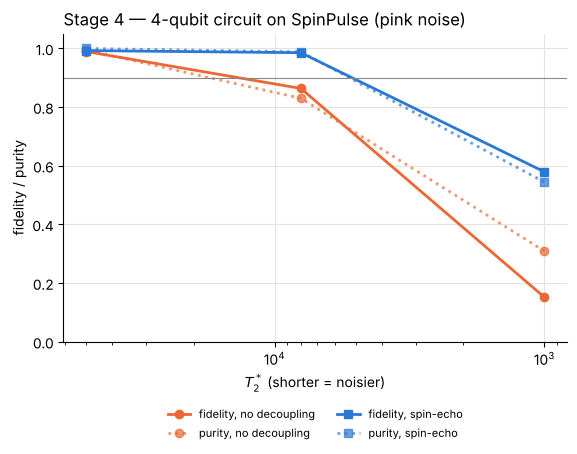

In [11]:
def stage4_circuit(K=4, d=2, t=0.5, reps=2):
    _, Cmat = build_generator(K, d, LAM, Q)
    psi0 = initial_state(K, d, OBS, LAM, Q); psi0 = psi0 / np.linalg.norm(psi0)
    n = K * int(np.log2(d))
    qc = QuantumCircuit(n); qc.append(StatePreparation(psi0), range(n))
    qc.compose(trotter_circuit(pauli_decomposition(Cmat), t, reps), inplace=True)
    return qc, Statevector(qc).data

def noisy_run(circuit, ideal, t2s, use_dd, **kwargs):
    channel, isa = spinpulse_channel(circuit, t2s, use_dd=use_dd, **kwargs)
    zero = np.zeros(2**circuit.num_qubits); zero[0] = 1.0       # the circuit prepares psi0 itself
    rho = np.asarray(DensityMatrix(zero).evolve(channel).data)
    return {"purity": float(np.real(np.trace(rho @ rho))),
            "fidelity": float(np.real(np.conj(ideal) @ rho @ ideal)),
            "rzz": isa.count_ops().get('rzz', 0)}

qc4, ideal4 = stage4_circuit()
T2S = [1000, 8000, 50000]
np.random.seed(0)
res, t0 = {}, time.time()
for use_dd in (False, True):
    for t2s in T2S:
        r = res[(use_dd, t2s)] = noisy_run(qc4, ideal4, t2s, use_dd)
        print(f"{'spin-echo' if use_dd else 'no DD    '} T2* = {t2s:>6}: fidelity {r['fidelity']:.3f}, "
              f"purity {r['purity']:.3f}, RZZ gates {r['rzz']}")
print(f"{time.time() - t0:.0f} s")

fig, ax = plt.subplots(figsize=(6.5, 4))
for use_dd, col, mk in ((False, COL[1], 'o'), (True, COL[0], 's')):
    lab = "spin-echo" if use_dd else "no decoupling"
    ax.semilogx(T2S, [res[(use_dd, t)]["fidelity"] for t in T2S], mk + '-', color=col, label=f"fidelity, {lab}")
    ax.semilogx(T2S, [res[(use_dd, t)]["purity"] for t in T2S], mk + ':', color=col, alpha=0.7, label=f"purity, {lab}")
ax.axhline(0.9, color='#888', lw=0.8)
ax.invert_xaxis(); ax.set_ylim(0, 1.05)
ax.set_xlabel(r"$T_2^*$ (shorter = noisier)"); ax.set_ylabel("fidelity / purity")
ax.set_title("Stage 4 — 4-qubit circuit on SpinPulse (pink noise)", loc='left')
ax.legend(frameon=False, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=2)
plt.show()

> **Answers — Stage 4**
>
> 1. **Purity vs fidelity.** Fidelity is the measure that says whether the forecast is right; purity only says how mixed the state is, and a pure but wrong state (a coherent error) would still have purity 1. At $T_2^* = 1{,}000$ without decoupling, purity is about 0.30 but fidelity only 0.08–0.15 (two runs): purity overstates the quality of the output by a factor of 2–4.
> 2. **Spin-echo.** It helps strongly against this slow (pink) noise: fidelity rises from 0.08–0.15 to about 0.6 at $T_2^* = 1{,}000$, and from 0.86 to 0.98 at $T_2^* = 8{,}000$. Fidelity 0.9 needs $T_2^*$ between 8,000 and 50,000 without decoupling, but less than 8,000 with spin-echo. The compiled circuit has 162 two-qubit (RZZ) gates. With only 4 noise samples per point, results scatter between runs even with `np.random.seed(0)`: in two identical runs the fidelity at $T_2^* = 1{,}000$ without decoupling was 0.08 and 0.15; the other points moved by 0.03 or less.
> 3. **More sites** (from `kolmogorian_lorenz96_solution.ipynb`, $T_2^* = 8{,}000$, no decoupling): RZZ gates grow from 162 ($K = 4$) to 228 ($K = 5$) and 250 ($K = 6$), and fidelity falls from 0.90 to 0.62 and 0.36. Spin-echo fails at $K = 5$ and 6 because of the SpinPulse 1.1.3 bug.

---
## Report and pitch — reference answers

| Method | Value | Error vs Monte Carlo | Qubits or ensemble members | Cost |
|---|---|---|---|---|
| Monte Carlo ensemble | 0.1686 | ± 0.0033 (s.e.) | 100,000 members | about 30 s per ensemble here |
| Exact emulator, $d = 4$ | 0.1737 | +0.005 (1.5 s.e.) | 8 qubits (256 states) | under a second |
| Damping + circuit, noiseless, $d = 4$ | 0.1896 | +0.021 (6 s.e.) | 8 qubits; 512 Pauli rotations per step, 32 steps | 6 s (NumPy product formula) |
| Circuit on SpinPulse, $d = 2$ | — | — | 4 qubits | fidelity 0.86 at $T_2^* = 8{,}000$ without decoupling, 0.98 with spin-echo; 162 two-qubit gates |

**Pitch, reference answers.**
1. **What and where.** The algorithm computes the ensemble mean of a stochastic forecast, the quantity a weather centre gets from its ensemble (about 50 members), without running members. It replaces the ensemble stage of the forecasting chain, for one observable at a time.
2. **How close and what limited it.** Exactly emulated, 8 qubits reproduce the 100,000-member ensemble within its error (0.005 at $t = 1$). As a circuit with 32 steps per time unit, the first-order Trotter error (0.016) is the largest remaining error. On simulated spin qubits, the 4-qubit circuit keeps fidelity 0.9 only with $T_2^*$ above roughly $10^4$, or with spin-echo.
3. **What must change.** The damping needs fault-tolerant techniques (block encodings); readout cost grows exponentially with the anomaly size relative to the noise; and Monte Carlo is cheap at this size. An advantage requires very many variables, an observable that depends on few of them, a small anomaly, and fault-tolerant hardware.

## Extensions (only if you finish early)

- **Noise strength.** Repeat Stage 2 for $q = 0.5$ and $q = 8$. Which $d$ is needed? The noisy-start readout vector has squared norm $e^{\sum_k y_k^2}$, and the number of measurements needed on hardware grows with it: compute it against $q$.
- **Forcing.** Add a constant forcing $F$ to the Monte Carlo and see how large the disagreement with your $F = 0$ forecast becomes.
- **White noise.** Rerun Stage 4 with `noise_type=NoiseType.WHITE`. Does spin-echo still help? Why not?

## References

- Bravyi, Manson-Sawko, Zayats, Zhuk, *Quantum simulation of a noisy classical nonlinear dynamics*, arXiv:2507.06198 (2025)
- Bravyi, Byrne, Zayats, Zhuk, *Quantum algorithms for stochastic nonlinear differential equations*, arXiv:2606.08349 (2026)
- Lorenz (1996), *Predictability: a problem partly solved*, ECMWF Seminar on Predictability

> The supervisor notes (section *Extensions*) and Part 5 of `kolmogorian_lorenz96_solution.ipynb` give reference results for the noise-strength extension.